In [46]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

path = "Data/logistic_regression_outliers_practice.csv"
df = pd.read_csv(path)

df.head()

,study_hours,attendance,passed
0,7.97,79.20,1
1,4.95,82.49,1
2,8.73,54.22,1
3,7.28,70.79,1
4,1.85,52.08,0


In [3]:
df.shape

(126, 3)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  126 non-null    float64
 1   attendance   126 non-null    float64
 2   passed       126 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 3.1 KB


In [5]:
df.isnull().sum()

study_hours    0
attendance     0
passed         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

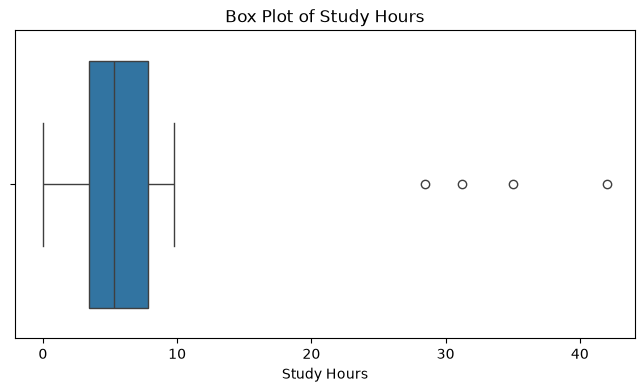

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.boxplot(x=df['study_hours'])
plt.title("Box Plot of Study Hours")
plt.xlabel("Study Hours")

plt.show()

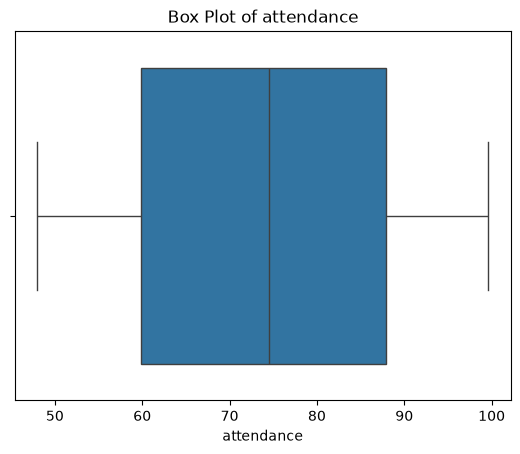

In [10]:
sns.boxplot(x = df['attendance'])
plt.title("Box Plot of attendance")
plt.xlabel("attendance")

plt.show()

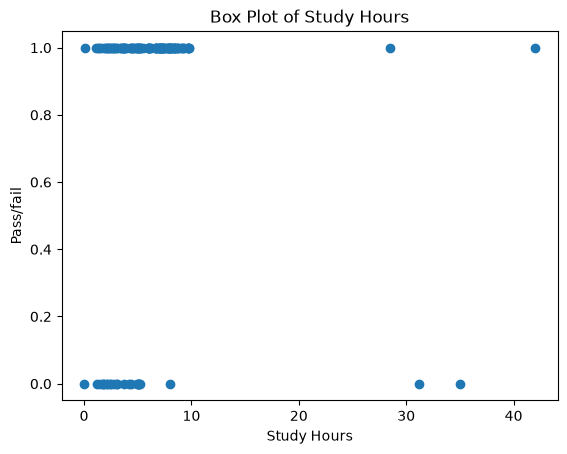

In [15]:
plt.scatter(x=df['study_hours'], y=df['passed'])
plt.title("Box Plot of Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Pass/fail")

plt.show()

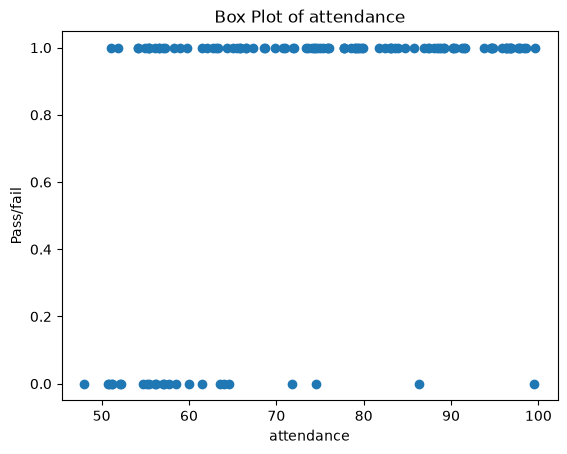

In [18]:
plt.scatter(x=df['attendance'], y=df['passed'])
plt.title("Box Plot of attendance")
plt.xlabel("attendance")
plt.ylabel("Pass/fail")

plt.show()

In [26]:
Q1 = df['attendance'].quantile(0.25)
Q3 = df['attendance'].quantile(0.75)

IQR = Q3 - Q1
print("IQR: ", IQR)

lower_limit_attendence = Q1 - 1.5 * IQR
upper_limit_attendence = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit_attendence)
print("Upper limit:", upper_limit_attendence)

IQR:  27.995000000000005
Lower limit: 17.86999999999999
Upper limit: 129.85000000000002


In [27]:
Q1 = df['study_hours'].quantile(0.25)
Q3 = df['study_hours'].quantile(0.75)

IQR = Q3 - Q1
print("IQR: ", IQR)

lower_limit_study_hours = Q1 - 1.5 * IQR
upper_limit_study_hours = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit_study_hours)
print("Upper limit:", upper_limit_study_hours)

IQR:  4.4225
Lower limit: -3.2287500000000007
Upper limit: 14.461250000000001


In [28]:

outliers_study = df[
    (df["study_hours"] < lower_limit_study_hours) |
    (df["study_hours"] > upper_limit_study_hours)
]

print("Number of outliers:", len(outliers_study))
print(outliers_study)


Number of outliers: 4
     study_hours  attendance  passed
120         28.5        72.0       1
122         35.0        63.5       0
123         42.0        55.0       1
125         31.2        48.0       0


In [31]:
outliers_attendence = df[
    (df['attendance'] < lower_limit_attendence) |
    (df['attendance'] > upper_limit_attendence)
]

print("Number of outliers:", len(outliers_attendence))
print(outliers_attendence)

Number of outliers: 0
Empty DataFrame
Columns: [study_hours, attendance, passed]
Index: []


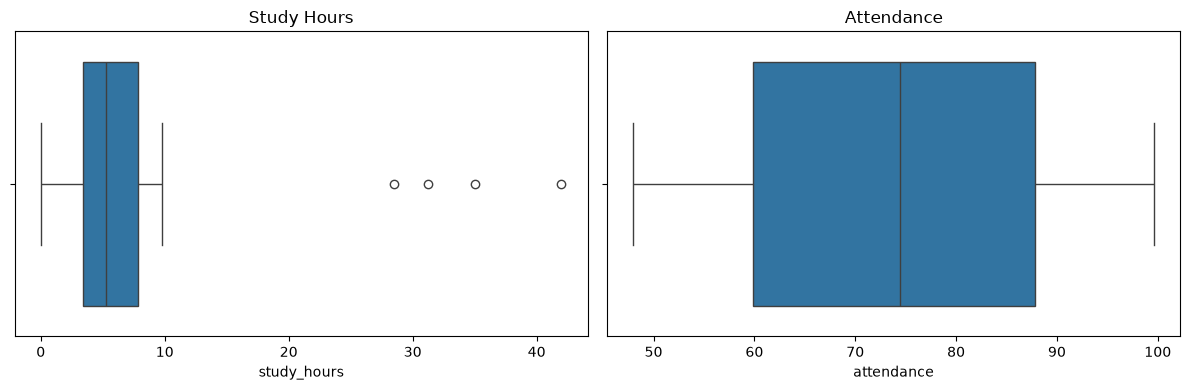

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df['study_hours'], ax=axes[0])
axes[0].set_title("Study Hours")

sns.boxplot(x=df['attendance'], ax=axes[1])
axes[1].set_title("Attendance")

plt.tight_layout()
plt.show()

In [38]:
df_clean = df.copy()

df_clean = df[
    (df_clean["study_hours"] >= lower_limit_study_hours) &
    (df_clean["study_hours"] <= upper_limit_study_hours)
]

df_clean.shape, df.shape

((122, 3), (126, 3))

In [42]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 122 entries, 0 to 124
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  122 non-null    float64
 1   attendance   122 non-null    float64
 2   passed       122 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 3.8 KB


In [62]:
scaler = StandardScaler()

X = df_clean.drop(columns=['passed'])
Y = df_clean['passed']

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

model = LogisticRegression()
model.fit(x_train_scaler, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [63]:
y_pred = model.predict(x_test_scaler)

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("f1 score: ", f1_score(y_test, y_pred))
confusion_matrix(y_test, y_pred)

Accuracy:  0.918918918918919
f1 score:  0.9523809523809523


array([[ 4,  3],
       [ 0, 30]])

In [56]:
model2 = LogisticRegression()
X = df.drop(columns=['passed'])
Y = df['passed']

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

model2.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [61]:
y_pred2 = model2.predict(x_test)

print("Accuracy: ", accuracy_score(y_test, y_pred2))
print("f1 score: ", f1_score(y_test, y_pred2))
confusion_matrix(y_test, y_pred2)

Accuracy:  0.7631578947368421
f1 score:  0.8524590163934426


array([[ 3,  7],
       [ 2, 26]])